# Predicting House Prices in King County, Washington

**Todd Sakai** · Capstone project, *Data Analysis with Python* (IBM Data Science Professional Certificate)

**Business question.** A real estate investment trust wants to enter the residential market. It needs a quick, defensible estimate of a home's market price from its features: size, rooms, location, condition and view.

**Data.** 21,613 home sales in King County, WA (which includes Seattle), May 2014 to May 2015, from the public [Kaggle house sales dataset](https://www.kaggle.com/harlfoxem/housesalesprediction).

**Approach.** Clean the data, explore which features move price, then compare five regression models of increasing complexity on R² (the share of price variation the model explains).

### Key results

| | |
|---|---|
| Best model | Ridge regression on 11 features with degree-2 polynomial terms |
| Accuracy on unseen homes | **R² = 0.70** (explains 70% of price variation in a 15% held-out test set) |
| Strongest single predictor | Living area (`sqft_living`), correlation 0.70 with price, R² = 0.49 alone |
| Tools | Python, pandas, NumPy, seaborn, matplotlib, scikit-learn |

## Setup and data

In [8]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 25)

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/FinalModule_Coursera/data/kc_house_data_NaN.csv"
df = pd.read_csv("kc_house_data_NaN.csv" if os.path.exists("kc_house_data_NaN.csv") else URL)
print(f"{df.shape[0]:,} sales, {df.shape[1]} columns")
df[["date", "price", "bedrooms", "bathrooms", "sqft_living", "grade", "waterfront", "lat", "long"]].head()

21,613 sales, 22 columns


,date,price,bedrooms,bathrooms,sqft_living,grade,waterfront,lat,long
0,20141013T000000,221900.0,3.0,1.00,1180,7,0,47.5112,-122.257
1,20141209T000000,538000.0,3.0,2.25,2570,7,0,47.7210,-122.319
2,20150225T000000,180000.0,2.0,1.00,770,6,0,47.7379,-122.233
3,20141209T000000,604000.0,4.0,3.00,1960,7,0,47.5208,-122.393
4,20150218T000000,510000.0,3.0,2.00,1680,8,0,47.6168,-122.045


## Data cleaning

The `id` and `Unnamed: 0` columns are row identifiers with no predictive value, so I drop them.

In [9]:
df.drop(["id", "Unnamed: 0"], axis=1, inplace=True)
df[["price", "bedrooms", "bathrooms", "sqft_living", "floors", "grade"]].describe().round(1)

,price,bedrooms,bathrooms,sqft_living,floors,grade
count,21613.0,21600.0,21603.0,21613.0,21613.0,21613.0
mean,540088.1,3.4,2.1,2079.9,1.5,7.7
std,367127.2,0.9,0.8,918.4,0.5,1.2
min,75000.0,1.0,0.5,290.0,1.0,1.0
25%,321950.0,3.0,1.8,1427.0,1.0,7.0
50%,450000.0,3.0,2.2,1910.0,1.5,7.0
75%,645000.0,4.0,2.5,2550.0,2.0,8.0
max,7700000.0,33.0,8.0,13540.0,3.5,13.0


A small number of homes are missing `bedrooms` or `bathrooms`. I fill those gaps with each column's mean so no sales are lost.

In [10]:
print("Missing before:", df[["bedrooms", "bathrooms"]].isnull().sum().to_dict())
for col in ["bedrooms", "bathrooms"]:
    df[col] = df[col].fillna(df[col].mean())
print("Missing after: ", df[["bedrooms", "bathrooms"]].isnull().sum().to_dict())

Missing before: {'bedrooms': 13, 'bathrooms': 10}
Missing after:  {'bedrooms': 0, 'bathrooms': 0}


## Exploratory analysis

### How many floors do homes have?

In [11]:
df["floors"].value_counts().to_frame()

,count
floors,
1.0,10680
2.0,8241
1.5,1910
3.0,613
2.5,161
3.5,8


### Does a waterfront view change the price spread?

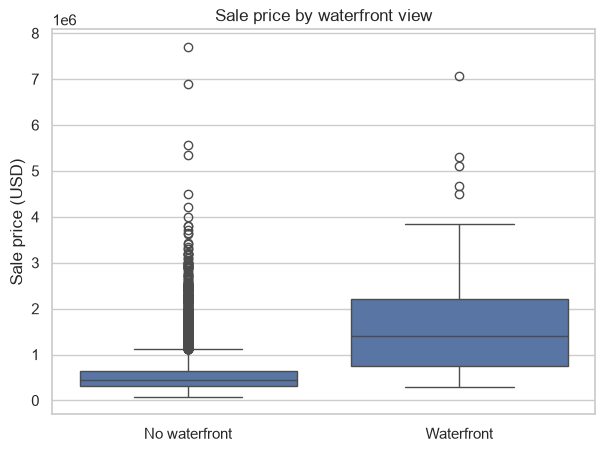

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(x="waterfront", y="price", data=df, ax=ax)
ax.set_xticklabels(["No waterfront", "Waterfront"])
ax.set(xlabel="", ylabel="Sale price (USD)", title="Sale price by waterfront view")
plt.show()

Homes without a waterfront view have far more high-price outliers, because they are 99% of the sample. Waterfront homes have a much higher median price.

### Is above-ground living area related to price?

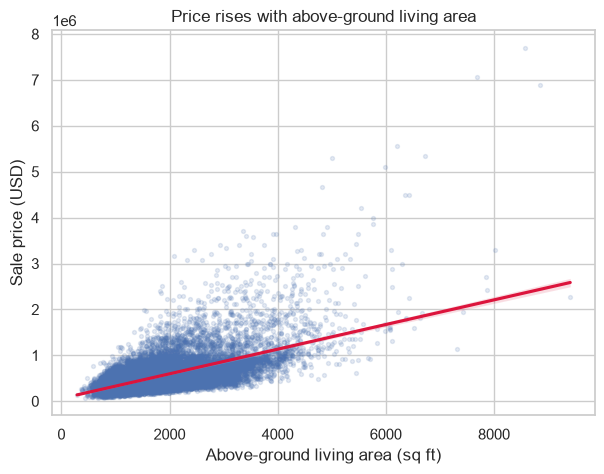

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(x="sqft_above", y="price", data=df, ax=ax,
            scatter_kws={"alpha": 0.15, "s": 8}, line_kws={"color": "crimson"})
ax.set(xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD)",
       title="Price rises with above-ground living area")
plt.show()

The relationship is clearly positive. Larger homes sell for more.

### Which features correlate most with price?

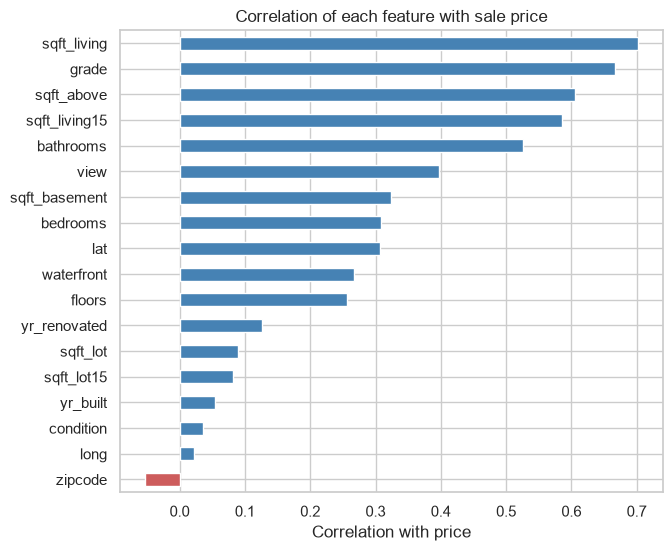

sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525738
Name: price, dtype: float64

In [14]:
corr = df.select_dtypes(include=np.number).corr()["price"].drop("price").sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "steelblue", "indianred"))
ax.set(xlabel="Correlation with price", title="Correlation of each feature with sale price")
plt.show()
corr.sort_values(ascending=False).head(5)

Living area (`sqft_living`), construction `grade` and above-ground area are the strongest single predictors. Location matters too: latitude (`lat`) is positive because homes further north, around Seattle, sell for more.

## Model development

I start with one feature and add complexity step by step, recording R² at each step.

In [15]:
results = {}
Y = df["price"]

lm = LinearRegression().fit(df[["long"]], Y)
results["Linear: longitude only"] = lm.score(df[["long"]], Y)

lm = LinearRegression().fit(df[["sqft_living"]], Y)
results["Linear: sqft_living only"] = lm.score(df[["sqft_living"]], Y)
{k: round(v, 4) for k, v in results.items()}

{'Linear: longitude only': 0.0005, 'Linear: sqft_living only': 0.4929}

Living area alone explains about half of the variation in price. Next I use eleven features together.

In [16]:
features = ["floors", "waterfront", "lat", "bedrooms", "sqft_basement", "view",
            "bathrooms", "sqft_living15", "sqft_above", "grade", "sqft_living"]
X = df[features]

lm = LinearRegression().fit(X, Y)
results["Linear: 11 features"] = lm.score(X, Y)

pipe = Pipeline([("scale", StandardScaler()),
                 ("polynomial", PolynomialFeatures(include_bias=False)),
                 ("model", LinearRegression())])
pipe.fit(X, Y)
results["Pipeline: scale + polynomial + linear"] = pipe.score(X, Y)
{k: round(v, 4) for k, v in results.items()}

{'Linear: longitude only': 0.0005,
 'Linear: sqft_living only': 0.4929,
 'Linear: 11 features': 0.6577,
 'Pipeline: scale + polynomial + linear': 0.7513}

These scores are measured on the same data the models were fit on, so they can overstate real performance. The next section tests on data the model has not seen.

## Model evaluation on held-out data

I hold out 15% of sales as a test set and fit Ridge regression, which shrinks coefficients (regularization strength alpha = 0.1) to reduce overfitting.

In [17]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=1)
print("Training samples:", x_train.shape[0], "| Test samples:", x_test.shape[0])

ridge = Ridge(alpha=0.1).fit(x_train, y_train)
test_results = {"Ridge: 11 features": ridge.score(x_test, y_test)}

pr = PolynomialFeatures(degree=2)
x_train_pr, x_test_pr = pr.fit_transform(x_train), pr.transform(x_test)
ridge_pr = Ridge(alpha=0.1).fit(x_train_pr, y_train)
test_results["Ridge: 11 features, degree-2 polynomial"] = ridge_pr.score(x_test_pr, y_test)
{k: round(v, 4) for k, v in test_results.items()}

Training samples: 18371 | Test samples: 3242


{'Ridge: 11 features': 0.6479,
 'Ridge: 11 features, degree-2 polynomial': 0.7003}

## Results

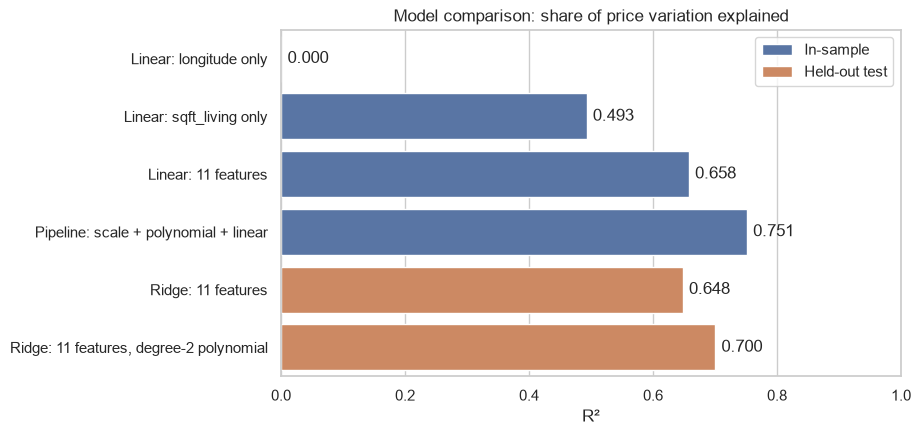

,Model,R²,Evaluated on
0,Linear: longitude only,0.0005,In-sample
1,Linear: sqft_living only,0.4929,In-sample
2,Linear: 11 features,0.6577,In-sample
3,Pipeline: scale + polynomial + linear,0.7513,In-sample
4,Ridge: 11 features,0.6479,Held-out test
5,"Ridge: 11 features, degree-2 polynomial",0.7003,Held-out test


In [18]:
summary = pd.DataFrame(
    [(k, v, "In-sample") for k, v in results.items()] +
    [(k, v, "Held-out test") for k, v in test_results.items()],
    columns=["Model", "R²", "Evaluated on"])
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=summary, y="Model", x="R²", hue="Evaluated on", dodge=False, ax=ax)
for i, v in enumerate(summary["R²"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.set(xlim=(0, 1), ylabel="", title="Model comparison: share of price variation explained")
ax.legend(loc="upper right")
plt.show()
summary.round(4)

## Conclusions

- **Size and quality drive price.** Living area and construction grade are the strongest predictors. Living area alone explains 49% of the variation in price.
- **Location matters, but not in a straight line.** Longitude alone explains almost nothing (R² of about 0.0005), yet latitude is positively correlated with price. Location effects are local, not a simple east-west gradient.
- **More features and interactions help.** Moving from one feature to eleven raised R² from 0.49 to 0.66. Adding squared and interaction terms raised it again, to 0.75 in-sample.
- **The gain holds on unseen data.** On the held-out test set, the polynomial Ridge model scored 0.70 against 0.65 for the plain Ridge model, so the extra terms capture real structure and not only noise.

**Recommendation.** For first-pass pricing of candidate properties, the trust can use the polynomial Ridge model. A typical estimate still misses part of the price, so it should screen deals, not replace an appraisal.

**Next steps.** Model log(price) to handle the long right tail of expensive homes; add zip code or neighborhood effects; tune the regularization strength alpha with cross-validation; and try tree-based models such as gradient boosting.